# Herbiers et CrossViT : segmentation, pondération par patch et interprétabilité

Projet du module Deep Learning, CY Tech 2025-2026 (Amine Filali, Haroun Joudi).

Classification binaire présence / absence d'épines sur 898 planches d'herbier numérisées. Chaque spécimen existe en deux versions : la planche complète (avec étiquettes, règle, code-barres) et une image segmentée où seule la plante reste. Le modèle est un CrossViT à deux branches (patchs 12x12 et 16x16, fusion par cross-attention) qui reçoit les deux images.

Ce notebook est celui qui a tourné sur le serveur d'entraînement (H100 80 Go). Les sorties des cellules d'entraînement et d'évaluation ont été gardées, les autres ont été vidées, et les identifiants d'accès aux données ont été retirés. Le même code, découpé en modules, est dans `src/`.

Contenu :

1. accès aux données (API privée, identifiants dans `.env`)
2. configuration et split stratifié 70/15/15
3. modèle CrossViT à deux images, modes A, B, C1, C2, O2
4. poids par patch (O3), attention rollout et IoU (O4), loss CE + IoU (O5)
5. entraînement des cinq configurations puis de la meilleure avec la loss IoU
6. évaluation sur le split test


In [ ]:
# ===========================================================================
# -- IMPORTS & SETUP --
# ===========================================================================

# dépendances : voir requirements.txt
import os
import random
import requests
import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import time
import math
import json
import pickle
from threading import Lock
from concurrent.futures import ThreadPoolExecutor, as_completed
from requests.adapters import HTTPAdapter
from io import BytesIO

# PIL imports with truncated image support
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True  # PREVENTS TRUNCATION ERRORS

# PyTorch imports
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Sklearn metrics
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix, classification_report

# Progress bars
from tqdm.auto import tqdm

print("imports ok")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")


In [ ]:
# Cache d'images partagé par les datasets (tout tient en RAM sur le serveur)
import gc
import torch

if 'GLOBAL_IMAGE_CACHE' not in globals():
    GLOBAL_IMAGE_CACHE = {}

def clear_ram_cache():
    global GLOBAL_IMAGE_CACHE
    GLOBAL_IMAGE_CACHE.clear()
    gc.collect()
    torch.cuda.empty_cache()
    print("cache vidé")

clear_ram_cache()


In [ ]:
# GPU disponible
import torch

print("torch version:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    i = torch.cuda.current_device()
    print("current device:", i)
    print("name:", torch.cuda.get_device_name(i))
    props = torch.cuda.get_device_properties(i)
    print("total VRAM (GB):", round(props.total_memory / 1024**3, 2))

torch version: 2.9.1+cu128
cuda available: True
current device: 0
name: NVIDIA H100 PCIe
total VRAM (GB): 79.1


In [ ]:
# Accès aux données
# Les images sont confidentielles (données du cours) : pendant le projet elles
# étaient servies par une petite API HTTPS (certificat client + basic auth).
# L'adresse et les identifiants viennent du fichier .env (voir .env.example).
import os

def load_dotenv(path=".env"):
    if not os.path.exists(path):
        return
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line and not line.startswith("#") and "=" in line:
                k, v = line.split("=", 1)
                os.environ.setdefault(k.strip(), v.strip().strip('"'))

load_dotenv()
BASE = os.environ["HERBARIUM_API_URL"].rstrip("/")
CERT = (os.environ["HERBARIUM_CLIENT_CERT"], os.environ["HERBARIUM_CLIENT_KEY"])
CA = os.environ.get("HERBARIUM_CA_CERT", True)
AUTH = (os.environ["HERBARIUM_API_USER"], os.environ.get("HERBARIUM_API_PASSWORD", ""))
CACHE_DIR = "./img_cache"

s = requests.Session()
adapter = HTTPAdapter(pool_connections=64, pool_maxsize=64, max_retries=0)
s.mount("https://", adapter)
s.mount("http://", adapter)
os.makedirs(CACHE_DIR, exist_ok=True)


In [ ]:
# Test de connexion
def ping():
    r = s.get(f"{BASE}/api/ids", cert=CERT, verify=CA, auth=AUTH, timeout=30)
    print("status:", r.status_code)
    print("content-type:", r.headers.get("content-type"))
    r.raise_for_status()
    print("ids:", len(r.json()["ids"]))

ping()

In [ ]:
# Téléchargement des images avec cache disque
import time
from threading import Lock

_cache_locks = {}
_locks_lock = Lock()

def _get_lock(path):
    """Get or create a lock for a specific cache file."""
    with _locks_lock:
        if path not in _cache_locks:
            _cache_locks[path] = Lock()
        return _cache_locks[path]
        
def _ext_from_headers(headers):
    ct = (headers.get("Content-Type") or "").split(";")[0].strip().lower()
    if ct == "image/jpeg": return ".jpg"
    if ct == "image/png":  return ".png"
    return ".img"

def _cache_path(img_id: str, kind: str, ext: str):
    return os.path.join(CACHE_DIR, f"{kind}_{img_id}{ext}")

def fetch_image(img_id: str, kind: str = "classic", timeout=30, max_retries=3) -> Image.Image:
    # 1. Check if cached
    for ext in [".jpg",".jpeg",".png",".img"]:
        p = os.path.join(CACHE_DIR, f"{kind}_{img_id}{ext}")
        if os.path.exists(p) and os.path.getsize(p) > 0:
            lock = _get_lock(p)
            with lock:
                try:
                    img = Image.open(p)
                    img.load()  # Force load to verify
                    return img.convert("RGB")
                except Exception as e:
                    # Corrupted cache, delete it
                    print(f"Cache corrompu {img_id}, re-téléchargement...")
                    try:
                        os.remove(p)
                    except:
                        pass
    # 2. Download with retry logic
    for attempt in range(max_retries):
        try:
            url = f"{BASE}/api/{kind}/{img_id}"
            with s.get(url, cert=CERT, verify=CA, auth=AUTH, stream=True, timeout=timeout) as r:
                r.raise_for_status()
                ext = _ext_from_headers(r.headers)
                p = _cache_path(img_id, kind, ext)
                p_temp = p + ".tmp"
                
                # Write to temp file first
                with open(p_temp, "wb") as f:
                    for chunk in r.iter_content(chunk_size=1024*1024):
                        if chunk:
                            f.write(chunk)
                
                # Verify download completed
                if os.path.getsize(p_temp) == 0:
                    raise IOError(f"Downloaded empty file for {img_id}")
                
                # Atomically rename to final path
                lock = _get_lock(p)
                with lock:
                    os.replace(p_temp, p)
                
                # Load and verify
                img = Image.open(p)
                img.load()
                return img.convert("RGB")
                
        except Exception as e:
            if attempt == max_retries - 1:
                raise RuntimeError(f"Failed to fetch {img_id} after {max_retries} attempts: {e}")
            print(f"Retry {attempt+1}/{max_retries} for {img_id}: {e}")
            time.sleep(0.5 * (attempt + 1))
    
def fetch_many(img_ids, kind="classic", workers=16, timeout=120):
    """
    Fetch many images concurrently. Returns dict {img_id: PIL.Image}.
    """
    results = {}

    def task(i):
        return i, fetch_image(i, kind=kind, timeout=timeout)

    with ThreadPoolExecutor(max_workers=workers) as ex:
        futures = [ex.submit(task, i) for i in img_ids]
        for f in as_completed(futures):
            try:
                img_id, im = f.result()
                results[img_id] = im
            except Exception as e:
                print("fetch failed:", kind, img_id, e)

    return results

In [ ]:
# Liste des identifiants
def list_ids():
    r = s.get(f"{BASE}/api/ids", cert=CERT, verify=CA, auth=AUTH, timeout=30)
    r.raise_for_status()
    return r.json()["ids"]

ids = list_ids()
len(ids), ids[:10]

In [ ]:
# Métadonnées d'un spécimen
def get_meta(img_id: str):
    r = s.get(f"{BASE}/api/meta/{img_id}", cert=CERT, verify=CA, auth=AUTH, timeout=30)
    r.raise_for_status()
    return r.json()

test_id = ids[0]
meta = get_meta(test_id)

print("test_id:", test_id)
print("meta keys:", meta.keys())
print("csv row:", meta["meta"])
print("classic file:", meta["classic_file"])
print("seg file:", meta["seg_file"])

In [ ]:
def show_grid(kind="classic", n=16, cols=4, seed=None, title=None, workers=16):
    if seed is not None:
        random.seed(seed)

    chosen = random.sample(ids, k=min(n, len(ids)))
    rows = (len(chosen) + cols - 1) // cols

    imgs = fetch_many(chosen, kind=kind, workers=workers)

    plt.figure(figsize=(3*cols, 3*rows))
    for i, img_id in enumerate(chosen, start=1):
        im = imgs.get(img_id) or Image.new("RGB", (256, 256))
        ax = plt.subplot(rows, cols, i)
        ax.imshow(im)
        ax.set_title(img_id, fontsize=8)
        ax.axis("off")

    plt.suptitle(title or f"Random grid: {kind}")
    plt.tight_layout()
    plt.show()

def show_pairs(n=8, seed=None, workers=16):
    if seed is not None:
        random.seed(seed)

    chosen = random.sample(ids, k=min(n, len(ids)))

    classic_imgs = fetch_many(chosen, kind="classic", workers=workers)
    seg_imgs     = fetch_many(chosen, kind="seg", workers=workers)

    plt.figure(figsize=(10, 3*n))
    for i, img_id in enumerate(chosen):
        ax1 = plt.subplot(n, 2, 2*i + 1)
        ax1.imshow(classic_imgs.get(img_id) or Image.new("RGB", (256, 256)))
        ax1.set_title(f"classic: {img_id}", fontsize=9)
        ax1.axis("off")

        ax2 = plt.subplot(n, 2, 2*i + 2)
        ax2.imshow(seg_imgs.get(img_id) or Image.new("RGB", (256, 256)))
        ax2.set_title(f"seg: {img_id}", fontsize=9)
        ax2.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
show_grid("classic", n=8, cols=4, workers=8)

In [ ]:
show_grid("seg", n=8, cols=4, workers=8)

In [ ]:
show_pairs(n=4, workers=8)

## Configuration

Hyperparamètres communs à tous les runs : images 224x224, patchs 12 (branche small, dim 192) et 16 (branche large, dim 384), 8 blocs, 8 têtes, MLP ratio 4, dropout 0.2, batch 64, AdamW lr 1e-5 avec cosine annealing, 5 époques. Les mêmes valeurs servent aux cinq configurations pour que la comparaison reste équitable.


In [ ]:
CONFIG = {
    # -----------------------------------------------------------------
    # Chargement des données
    # -----------------------------------------------------------------
    'BATCH_SIZE': 64,
    'NUM_WORKERS': 0,  # des workers > 0 faisaient planter le kernel avec le cache en RAM
    'PIN_MEMORY': True,
    'PREFETCH_FACTOR': None,  # Disabled for NUM_WORKERS=0
    'PERSISTENT_WORKERS': False,  # Disabled for NUM_WORKERS=0
    'USE_AMP': True,
    
    # -----------------------------------------------------------------
    # Entraînement
    # -----------------------------------------------------------------
    'LEARNING_RATE': 1e-5,
    'MIN_LR': 1e-6,
    'WEIGHT_DECAY': 1e-4,
    
    # -----------------------------------------------------------------
    # Augmentation (définie mais pas utilisée pour les runs finaux)
    # -----------------------------------------------------------------
    'HORIZONTAL_FLIP_PROB': 0.5,
    'ROTATION_DEGREES': 15,
    'COLOR_JITTER_BRIGHTNESS': 0.2,
    'COLOR_JITTER_CONTRAST': 0.2,
    'IMAGE_TYPE': 'classic',
    
    # -----------------------------------------------------------------
    # Architecture (DualImageCrossViT)
    # -----------------------------------------------------------------
    'IMAGE_SIZE': 224,
    'PATCH_SIZE_SMALL': 12,
    'PATCH_SIZE_LARGE': 16,
    'EMBED_DIM_SMALL': 192,
    'EMBED_DIM_LARGE': 384,
    'DEPTH': 8,
    'NUM_HEADS': 8,
    'MLP_RATIO': 4,
    'QKV_BIAS': True,
    'DROPOUT': 0.2,
    'ATTENTION_DROPOUT': 0.1,
    'NUM_CLASSES': 2,
    
    # -----------------------------------------------------------------
    # Reproductibilité
    # -----------------------------------------------------------------
    'SEED': 42,
    'DETERMINISTIC': False,
    'BENCHMARK': True
}


In [ ]:
import sys
import os
from PIL import Image
# ===========================================================================
# -- REPRODUCTIBILITÉ - Configuration des graines aléatoires --
# ===========================================================================


def set_seed(seed: int = 42):
    """
    Configure toutes les graines aléatoires pour garantir la reproductibilité.
    
    Cette fonction fixe les graines pour:
    - Python random
    - NumPy
    - PyTorch (CPU et GPU)
    - Hash Python (pour dictionnaires, sets)
    - CuDNN (backend CUDA)
    
    Args:
        seed: Valeur de la graine aléatoire (défaut: 42)
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    
    # ------- Fixer la graine de hash Python pour comportement déterministe -------
    os.environ['PYTHONHASHSEED'] = str(seed)
    
    # ------- Configuration CuDNN pour reproductibilité -------
    if CONFIG['DETERMINISTIC']:
        # Mode déterministe: résultats reproductibles mais peut réduire les performances
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        print("Mode déterministe CuDNN activé (reproductibilité maximale)")
        print("Note: Peut réduire légèrement les performances (~5-10%)")
    else:
        # Mode benchmark: performances optimales mais résultats peuvent varier
        torch.backends.cudnn.benchmark = True  
        torch.backends.cudnn.deterministic = False
        print("Mode benchmark CuDNN activé (performances maximales)")


set_seed(CONFIG['SEED'])


# =============================================================================
#  -- Afficher les informations d'environnement pour reproductibilité --
# =============================================================================


print("\n" + "=" * 80)
print("INFORMATIONS D'ENVIRONNEMENT (Pour reproductibilité)")
print("=" * 80)


# ------- Versions des librairies -------
print(f"Python: {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA: {torch.version.cuda if torch.cuda.is_available() else 'Non disponible'}")
print(f"cuDNN: {torch.backends.cudnn.version() if torch.cuda.is_available() else 'Non disponible'}")
print(f"NumPy: {np.__version__}")
print(f"PIL: {Image.__version__}")


# ------- Configuration de reproductibilité -------
print(f"\nGraine aléatoire: {CONFIG['SEED']}")
print(f"Mode déterministe: {CONFIG['DETERMINISTIC']}")
print(f"CuDNN Benchmark: {CONFIG['BENCHMARK']}")


print("=" * 80)


# ------- Configurer les options d'affichage pour une meilleure lisibilité -------
torch.set_printoptions(precision=4, sci_mode=False, linewidth=120)
np.set_printoptions(precision=4, suppress=True, linewidth=120)


print("\nConfiguration de reproductibilité terminée\n")



 Mode benchmark CuDNN activé (performances maximales)

 INFORMATIONS D'ENVIRONNEMENT (Pour reproductibilité)
   Python: 3.13.5
   PyTorch: 2.9.1+cu128
   CUDA: 12.8
   cuDNN: 91002
   NumPy: 2.2.6
    PIL: 12.0.0

   Graine aléatoire: 42
   Mode déterministe: False
   CuDNN Benchmark: True

 Configuration de reproductibilité terminée



In [ ]:
# ===============================================================================
# -- CHARGEMENT DES DONNÉES - API avec tracking et gestion d'erreurs robuste --
# ===============================================================================

from tqdm.auto import tqdm
from collections import Counter

def get_all_metadata():
    """
    Récupère les métadonnées de toutes les images depuis l'API.
    
    Returns:
        list: Liste de dictionnaires de métadonnées pour chaque image
        
    Raises:
        Exception: Si la connexion à l'API échoue
    """
    print("Récupération des métadonnées du dataset...")
    print("-" * 80)
    
    try:
        # -------------- Récupérer la liste de tous les IDs d'images -------
        ids_response = s.get(f"{BASE}/api/ids", cert=CERT, verify=CA, auth=AUTH, timeout=30)
        ids_response.raise_for_status()
        all_ids = ids_response.json()["ids"]
        
        print(f"{len(all_ids)} images trouvées dans le dataset")
        
    except Exception as e:
        print(f"Erreur lors de la récupération des IDs: {e}")
        raise
    
    # ------- Récupérer les métadonnées pour chaque image avec barre de progression -------
    metadata_list = []
    failed_ids = []
    
    print(f"\nTéléchargement des métadonnées...")
    for img_id in tqdm(all_ids, desc="  Chargement", ncols=100):
        try:
            meta_response = s.get(
                f"{BASE}/api/meta/{img_id}",
                cert=CERT,
                verify=CA,
                auth=AUTH,
                timeout=30
            )
            meta_response.raise_for_status()
            metadata = meta_response.json()
            metadata_list.append(metadata)
            
        except Exception as e:
            failed_ids.append(img_id)
            tqdm.write(f"    Échec pour {img_id}: {e}")
            continue
    
    # ------- Afficher le résumé -------
    print(f"\nMétadonnées chargées avec succès: {len(metadata_list)}/{len(all_ids)}")
    if failed_ids:
        print(f"Échecs: {len(failed_ids)} images")
        print(f"IDs échoués: {', '.join(failed_ids[:5])}{'...' if len(failed_ids) > 5 else ''}")
    
    print("-" * 80)
    return metadata_list

def analyze_dataset(metadata_list):
    """
    Analyse les statistiques du dataset.
    
    Args:
        metadata_list: Liste des métadonnées
        
    Returns:
        dict: Statistiques du dataset
    """
    print("\nAnalyse du dataset...")
    print("-" * 80)
    
    # Compter les classes
    labels = [int(m['meta']['epines']) for m in metadata_list]
    class_counts = Counter(labels)
    
    stats = {
        'total_samples': len(metadata_list),
        'class_0_count': class_counts[0],
        'class_1_count': class_counts[1],
        'class_distribution': {
            'sans_epines': class_counts[0] / len(metadata_list) * 100,
            'avec_epines': class_counts[1] / len(metadata_list) * 100
        }
    }
    
    # ------- Afficher les statistiques -------
    print(f"Total d'échantillons: {stats['total_samples']}")
    print(f"\nDistribution des classes:")
    print(f"• Classe 0 (sans épines): {stats['class_0_count']:4d} ({stats['class_distribution']['sans_epines']:.1f}%)")
    print(f"• Classe 1 (avec épines): {stats['class_1_count']:4d} ({stats['class_distribution']['avec_epines']:.1f}%)")
    
    # ------- Calculer le ratio de déséquilibre -------
    balance_ratio = min(stats['class_0_count'], stats['class_1_count']) / max(stats['class_0_count'], stats['class_1_count'])
    print(f"\nRatio d'équilibre: {balance_ratio:.3f}")
    if balance_ratio < 0.8:
        print(f"Dataset déséquilibré - Pondération de classe recommandée")
    else:
        print(f"Dataset relativement équilibré")
    
    print("-" * 80)
    return stats

def create_stratified_splits(metadata_list, train_ratio=0.7, val_ratio=0.15, test_ratio=0.15):
    """
    Crée des splits train/val/test stratifiés.
    
    Stratification: garantit que chaque split contient la même proportion de classes.
    
    Args:
        metadata_list: Liste des métadonnées
        train_ratio: Proportion pour l'entraînement (défaut: 0.7)
        val_ratio: Proportion pour la validation (défaut: 0.15)
        test_ratio: Proportion pour le test (défaut: 0.15)
        
    Returns:
        tuple: (train_data, val_data, test_data, class_weights)
    """
    print(f"\nCréation des splits stratifiés...")
    print(f"Ratios: Train {train_ratio:.0%} / Val {val_ratio:.0%} / Test {test_ratio:.0%}")
    print("-" * 80)
    
    # ------- Vérifier que les ratios somment à 1.0 -------
    assert abs(train_ratio + val_ratio + test_ratio - 1.0) < 1e-6, "Les ratios doivent sommer à 1.0"
    
    # ------- Séparer par classe pour stratification -------
    class_0_samples = [m for m in metadata_list if int(m['meta']['epines']) == 0]
    class_1_samples = [m for m in metadata_list if int(m['meta']['epines']) == 1]
    
    # ------- Mélanger chaque classe de manière reproductible
    random.shuffle(class_0_samples)
    random.shuffle(class_1_samples)
    
    # Fonction helper pour split stratifié
    def split_class_samples(samples, train_r, val_r):
        """Split échantillons d'une classe selon les ratios."""
        n = len(samples)
        train_end = int(n * train_r)
        val_end = train_end + int(n * val_r)
        return samples[:train_end], samples[train_end:val_end], samples[val_end:]
    
    # Split chaque classe
    train_0, val_0, test_0 = split_class_samples(class_0_samples, train_ratio, val_ratio)
    train_1, val_1, test_1 = split_class_samples(class_1_samples, train_ratio, val_ratio)
    
    # Combiner et mélanger
    train_data = train_0 + train_1
    val_data = val_0 + val_1
    test_data = test_0 + test_1
    
    random.shuffle(train_data)
    random.shuffle(val_data)
    random.shuffle(test_data)
    
    # Afficher les statistiques des splits
    print(f"Splits créés:")
    print(f"\nTrain: {len(train_data):4d} échantillons ({len(train_data)/len(metadata_list):.1%})")
    print(f"├─ Classe 0: {len(train_0):4d} ({len(train_0)/len(train_data):.1%})")
    print(f"└─ Classe 1: {len(train_1):4d} ({len(train_1)/len(train_data):.1%})")
    
    print(f"\nVal:   {len(val_data):4d} échantillons ({len(val_data)/len(metadata_list):.1%})")
    print(f"├─ Classe 0: {len(val_0):4d} ({len(val_0)/len(val_data):.1%})")
    print(f"└─ Classe 1: {len(val_1):4d} ({len(val_1)/len(val_data):.1%})")
    
    print(f"\nTest:  {len(test_data):4d} échantillons ({len(test_data)/len(metadata_list):.1%})")
    print(f"├─ Classe 0: {len(test_0):4d} ({len(test_0)/len(test_data):.1%})")
    print(f"└─ Classe 1: {len(test_1):4d} ({len(test_1)/len(test_data):.1%})")
    
    # Calculer les poids de classe pour loss pondéré
    total_train = len(train_data)
    count_0 = len(train_0)
    count_1 = len(train_1)
    
    # Poids inversement proportionnels à la fréquence de classe
    weight_0 = total_train / (2 * count_0)
    weight_1 = total_train / (2 * count_1)
    class_weights = torch.tensor([weight_0, weight_1], dtype=torch.float32)
    
    print(f"\nPoids de classe (pour loss pondéré):")
    print(f"• Classe 0: {weight_0:.3f}")
    print(f"• Classe 1: {weight_1:.3f}")
    print(f"Ratio: {weight_1/weight_0:.3f}:1")
    
    print("-" * 80)
    
    return train_data, val_data, test_data, class_weights

# =============================================================================
# -- EXÉCUTION - Charger et analyser le dataset -- 
# =============================================================================

print("\n" + "=" * 80)
print("DÉMARRAGE DU CHARGEMENT DES DONNÉES")
print("=" * 80)

# ------- Charger les métadonnées -------
all_metadata = get_all_metadata()

# ------- Analyser le dataset -------
dataset_stats = analyze_dataset(all_metadata)

# ------- Créer les splits stratifiés -------
train_metadata, val_metadata, test_metadata, class_weights = create_stratified_splits(
    all_metadata,
    train_ratio=0.7,
    val_ratio=0.15,
    test_ratio=0.15
)

print("\n" + "=" * 80)
print("CHARGEMENT DES DONNÉES TERMINÉ")
print("=" * 80)
print(f"Dataset prêt pour l'entraînement!")
print("=" * 80 + "\n")



 DÉMARRAGE DU CHARGEMENT DES DONNÉES
 Récupération des métadonnées du dataset...
--------------------------------------------------------------------------------
   898 images trouvées dans le dataset

   Téléchargement des métadonnées...



   Métadonnées chargées avec succès: 898/898
--------------------------------------------------------------------------------

 Analyse du dataset...
--------------------------------------------------------------------------------
   Total d'échantillons: 898

   Distribution des classes:
     • Classe 0 (sans épines):  407 (45.3%)
     • Classe 1 (avec épines):  491 (54.7%)

    Ratio d'équilibre: 0.829
      Dataset relativement équilibré
--------------------------------------------------------------------------------

 Création des splits stratifiés...
   Ratios: Train 70% / Val 15% / Test 15%
--------------------------------------------------------------------------------
   Splits créés:

      Train:  627 échantillons (69.8%)
        ├─ Classe 0:  284 (45.3%)
        └─ Classe 1:  343 (54.7%)

      Val:    134 échantillons (14.9%)
        ├─ Classe 0:   61 (45.5%)
        └─ Classe 1:   73 (54.5%)

      Test:   137 échantillons (15.3%)
        ├─ Classe 0:   62 (45.3%)
       

In [ ]:
# ===========================================================================
# -- PYTORCH DATASET WITH MULTI-IMAGE TYPE SUPPORT + IN-MEMORY CACHING --
# ===========================================================================

class HerbiersDataset(Dataset):
    """
    Enhanced dataset supporting classic, segmented, and mixed image types.
    Features in-memory caching for maximum performance.
    """
    def __init__(self, metadata_list, transform=None, preload=False, image_type='classic'):
        self.metadata = metadata_list
        self.transform = transform
        self.image_type = image_type
        self.image_cache = GLOBAL_IMAGE_CACHE
        
        # Pre-load ALL images into RAM for fast training
        if preload:
            print(f"\n{'='*80}")
            print(f"PRÉ-CHARGEMENT DES IMAGES EN RAM")
            print(f"{'='*80}")
            print(f"Type d'images: {self.image_type}")
            print(f"Nombre d'images: {len(metadata_list)}")
            
            # Determine which image kinds to load
            kinds_to_load = []
            if self.image_type in ['classic', 'mixed']:
                kinds_to_load.append('classic')
            if self.image_type in ['segmented', 'mixed']:
                kinds_to_load.append('seg')
            
            # Load each kind
            for kind in kinds_to_load:
                print(f"\nChargement {kind}...")
                failed_count = 0
                for meta in tqdm(metadata_list, desc=f"  {kind.capitalize()}"):
                    img_id = meta['id']
                    cache_key = f"{kind}_{img_id}"
                    try:
                        self.image_cache[cache_key] = fetch_image(img_id, kind=kind, timeout=30)
                    except Exception as e:
                        failed_count += 1
                        if failed_count <= 5:  # Only print first 5 errors
                            print(f"Échec {img_id}: {str(e)[:60]}")
                
                if failed_count > 0:
                    print(f"Total échecs: {failed_count}/{len(metadata_list)}")
            
            print(f"\nPré-chargement terminé: {len(self.image_cache)} images en RAM")
            print(f"{'='*80}\n")
    
    def __len__(self):
        return len(self.metadata)
    
    def __getitem__(self, idx):
        meta = self.metadata[idx]
        img_id = meta['id']
        label = int(meta['meta']['epines'])
        
        try:
            if self.image_type == 'mixed':
                # Mixed mode: concatenate classic and segmented as 6 channels
                classic_key = f"classic_{img_id}"
                seg_key = f"seg_{img_id}"
                
                if classic_key in self.image_cache and seg_key in self.image_cache:
                    classic_img = self.image_cache[classic_key].copy()
                    seg_img = self.image_cache[seg_key].copy()
                    
                    # Convert both to tensors
                    if self.transform:
                        classic_tensor = self.transform(classic_img)
                        seg_tensor = self.transform(seg_img)
                    else:
                        classic_tensor = transforms.ToTensor()(classic_img)
                        seg_tensor = transforms.ToTensor()(seg_img)
                    
                    # Concatenate along channel dimension (3+3=6 channels)
                    image = torch.cat([classic_tensor, seg_tensor], dim=0)
                    return image, label
                else:
                    # Fallback if one is missing
                    cache_key = classic_key if classic_key in self.image_cache else seg_key
                    image = self.image_cache[cache_key].copy()
                    
            else:
                # Classic or Segmented mode
                kind = 'seg' if self.image_type == 'segmented' else 'classic'
                cache_key = f"{kind}_{img_id}"
                
                if cache_key in self.image_cache:
                    image = self.image_cache[cache_key].copy()
                else:
                    # Fallback: fetch on-demand if not cached
                    image = fetch_image(img_id, kind=kind, timeout=30)
            
            if self.transform and self.image_type != 'mixed':
                image = self.transform(image)
            
            return image, label
            
        except Exception as e:
            print(f"Erreur chargement image {img_id}: {e}")
            # Return black image as fallback to prevent crash
            if self.transform:
                black_img = Image.new('RGB', (CONFIG['IMAGE_SIZE'], CONFIG['IMAGE_SIZE']), (0, 0, 0))
                image = self.transform(black_img)
            else:
                image = torch.zeros(3, CONFIG['IMAGE_SIZE'], CONFIG['IMAGE_SIZE'])
            return image, label

# =============================================================================
# TRANSFORMS
# =============================================================================

train_transform = transforms.Compose([
    transforms.Resize((CONFIG['IMAGE_SIZE'], CONFIG['IMAGE_SIZE'])),
    transforms.RandomHorizontalFlip(p=CONFIG['HORIZONTAL_FLIP_PROB']),
    transforms.RandomRotation(CONFIG['ROTATION_DEGREES']),
    transforms.ColorJitter(
        brightness=CONFIG['COLOR_JITTER_BRIGHTNESS'],
        contrast=CONFIG['COLOR_JITTER_CONTRAST']
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((CONFIG['IMAGE_SIZE'], CONFIG['IMAGE_SIZE'])),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# =============================================================================
# CREATE DATASETS AND DATALOADERS
# =============================================================================

print("\nCréation des datasets...")

# Create datasets with preloading
train_dataset = HerbiersDataset(
    train_metadata, 
    transform=train_transform, 
    preload=False,
    image_type=CONFIG['IMAGE_TYPE']
)

val_dataset = HerbiersDataset(
    val_metadata, 
    transform=val_transform, 
    preload=False,
    image_type=CONFIG['IMAGE_TYPE']
)

test_dataset = HerbiersDataset(
    test_metadata, 
    transform=val_transform,
    preload=False,
    image_type=CONFIG['IMAGE_TYPE']
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG['BATCH_SIZE'],
    shuffle=True,
    num_workers=CONFIG['NUM_WORKERS'],
    pin_memory=CONFIG['PIN_MEMORY'],
    prefetch_factor=CONFIG['PREFETCH_FACTOR'],
    persistent_workers=CONFIG['PERSISTENT_WORKERS']
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG['BATCH_SIZE'],
    shuffle=False,
    num_workers=CONFIG['NUM_WORKERS'],
    pin_memory=CONFIG['PIN_MEMORY'],
    prefetch_factor=CONFIG['PREFETCH_FACTOR'],
    persistent_workers=CONFIG['PERSISTENT_WORKERS']
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG['BATCH_SIZE'],
    shuffle=False,
    num_workers=CONFIG['NUM_WORKERS'],
    pin_memory=CONFIG['PIN_MEMORY'],
    prefetch_factor=CONFIG['PREFETCH_FACTOR'],
    persistent_workers=CONFIG['PERSISTENT_WORKERS']
)

print(f"\nDataLoaders créés avec succès!")
print(f"Train batches: {len(train_loader)}")
print(f"Val batches:   {len(val_loader)}")
print(f"Test batches:  {len(test_loader)}")
print(f"Images en RAM: {len(train_dataset.image_cache) + len(val_dataset.image_cache) + len(test_dataset.image_cache)} images")
print(f"Type d'images: {CONFIG['IMAGE_TYPE']}")

print("\nCe dataset (une image par échantillon) sert aux visualisations ;")
print("l'entraînement utilise DualImageDataset (planche + segmentée) plus bas.")


In [ ]:
# ===========================================================================
# CrossViT - 2 IMAGES + 5 MODES (A, B, C1, C2, O2)
# ===========================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
from einops import rearrange, repeat
from einops.layers.torch import Rearrange

# Patch Embedding
class PatchEmbed(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_chans=3, embed_dim=768):
        super().__init__()
        num_patches = (img_size // patch_size) ** 2
        self.img_size = img_size
        self.patch_size = patch_size
        self.num_patches = num_patches
        
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)
    
    def forward(self, x):
        B, C, H, W = x.shape
        x = self.proj(x).flatten(2).transpose(1, 2)
        return x

# Multi-head Attention
class Attention(nn.Module):
    def __init__(self, dim, num_heads=8, qkv_bias=False, attn_drop=0., proj_drop=0.):
        super().__init__()
        self.num_heads = num_heads
        head_dim = dim // num_heads
        self.scale = head_dim ** -0.5
        
        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop)
    
    def forward(self, x):
        B, N, C = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, C // self.num_heads).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        
        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)
        attn_weights = attn  # Save for rollout
        attn = self.attn_drop(attn)
        
        x = (attn @ v).transpose(1, 2).reshape(B, N, C)
        x = self.proj(x)
        x = self.proj_drop(x)
        
        return x, attn_weights

# Transformer Block
class Block(nn.Module):
    def __init__(self, dim, num_heads, mlp_ratio=4., qkv_bias=False, drop=0., attn_drop=0.):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = Attention(dim, num_heads=num_heads, qkv_bias=qkv_bias, attn_drop=attn_drop, proj_drop=drop)
        self.norm2 = nn.LayerNorm(dim)
        mlp_hidden_dim = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(
            nn.Linear(dim, mlp_hidden_dim),
            nn.GELU(),
            nn.Dropout(drop),
            nn.Linear(mlp_hidden_dim, dim),
            nn.Dropout(drop)
        )
    
    def forward(self, x):
        attn_out, attn_weights = self.attn(self.norm1(x))
        x = x + attn_out
        x = x + self.mlp(self.norm2(x))
        return x, attn_weights

# Vision Transformer
class VisionTransformer(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_chans=3, embed_dim=768, depth=12, num_heads=12, mlp_ratio=4., qkv_bias=True, drop_rate=0., attn_drop_rate=0.):
        super().__init__()
        self.patch_embed = PatchEmbed(img_size, patch_size, in_chans, embed_dim)
        num_patches = self.patch_embed.num_patches
        
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        self.pos_drop = nn.Dropout(p=drop_rate)
        
        self.blocks = nn.ModuleList([
            Block(embed_dim, num_heads, mlp_ratio, qkv_bias, drop_rate, attn_drop_rate)
            for _ in range(depth)
        ])
        
        self.norm = nn.LayerNorm(embed_dim)
        
        # Initialize
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
    
    def forward(self, x):
        B = x.shape[0]
        x = self.patch_embed(x)
        
        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)
        x = x + self.pos_embed
        x = self.pos_drop(x)
        
        attn_weights_list = []
        for blk in self.blocks:
            x, attn_weights = blk(x)
            attn_weights_list.append(attn_weights)
        
        x = self.norm(x)
        return x, attn_weights_list

# Cross-Attention Fusion
class CrossAttentionFusion(nn.Module):
    def __init__(self, dim1, dim2, num_heads=4):
        super().__init__()
        self.num_heads = num_heads
        # Project to same dimension if different
        self.proj1 = nn.Linear(dim1, dim2) if dim1 != dim2 else nn.Identity()
        self.cross_attn = nn.MultiheadAttention(dim2, num_heads, batch_first=True)
        
    def forward(self, tokens1, tokens2):
        tokens1_proj = self.proj1(tokens1)
        # Cross-attention: query=tokens2, key=value=tokens1
        fused, attn_weights = self.cross_attn(tokens2, tokens1_proj, tokens1_proj)
        return fused, attn_weights

# MAIN MODEL: Dual-Image CrossViT
class DualImageCrossViT(nn.Module):
    """
    CrossViT acceptant 2 images (nonseg + seg)
    
    Modes:
    - 'A': nonseg seulement (1 branche Large)
    - 'B': seg seulement (1 branche Large)
    - 'C1': nonseg→Small, seg→Large + fusion
    - 'C2': nonseg→Large, seg→Small + fusion
    - 'O2': 2 branches MÊME résolution + fusion
    """
    
    def __init__(self, num_classes=2, img_size=224,
                 patch_size_small=12, patch_size_large=16,
                 embed_dim_small=96, embed_dim_large=192,
                 depth=4, num_heads=3, mlp_ratio=2,
                 qkv_bias=True, drop_rate=0.1, attn_drop_rate=0.1,
                 in_chans=3, mode='O2'):
        super().__init__()
        self.mode = mode
        self.num_classes = num_classes
        
        if mode == 'A':
            # Seulement nonseg
            self.branch_nonseg = VisionTransformer(
                img_size=img_size, patch_size=patch_size_large, in_chans=in_chans,
                embed_dim=embed_dim_large, depth=depth, num_heads=num_heads,
                mlp_ratio=mlp_ratio, qkv_bias=qkv_bias, drop_rate=drop_rate, attn_drop_rate=attn_drop_rate
            )
            self.head = nn.Linear(embed_dim_large, num_classes)
            
        elif mode == 'B':
            # Seulement seg
            self.branch_seg = VisionTransformer(
                img_size=img_size, patch_size=patch_size_large, in_chans=in_chans,
                embed_dim=embed_dim_large, depth=depth, num_heads=num_heads,
                mlp_ratio=mlp_ratio, qkv_bias=qkv_bias, drop_rate=drop_rate, attn_drop_rate=attn_drop_rate
            )
            self.head = nn.Linear(embed_dim_large, num_classes)
            
        elif mode == 'C1':
            # nonseg→Small, seg→Large
            self.branch_nonseg = VisionTransformer(
                img_size=img_size, patch_size=patch_size_small, in_chans=in_chans,
                embed_dim=embed_dim_small, depth=depth, num_heads=num_heads,
                mlp_ratio=mlp_ratio, qkv_bias=qkv_bias, drop_rate=drop_rate, attn_drop_rate=attn_drop_rate
            )
            self.branch_seg = VisionTransformer(
                img_size=img_size, patch_size=patch_size_large, in_chans=in_chans,
                embed_dim=embed_dim_large, depth=depth, num_heads=num_heads,
                mlp_ratio=mlp_ratio, qkv_bias=qkv_bias, drop_rate=drop_rate, attn_drop_rate=attn_drop_rate
            )
            self.fusion = CrossAttentionFusion(embed_dim_small, embed_dim_large, num_heads)
            self.head = nn.Linear(embed_dim_large, num_classes)
            
        elif mode == 'C2':
            # nonseg→Large, seg→Small
            self.branch_nonseg = VisionTransformer(
                img_size=img_size, patch_size=patch_size_large, in_chans=in_chans,
                embed_dim=embed_dim_large, depth=depth, num_heads=num_heads,
                mlp_ratio=mlp_ratio, qkv_bias=qkv_bias, drop_rate=drop_rate, attn_drop_rate=attn_drop_rate
            )
            self.branch_seg = VisionTransformer(
                img_size=img_size, patch_size=patch_size_small, in_chans=in_chans,
                embed_dim=embed_dim_small, depth=depth, num_heads=num_heads,
                mlp_ratio=mlp_ratio, qkv_bias=qkv_bias, drop_rate=drop_rate, attn_drop_rate=attn_drop_rate
            )
            self.fusion = CrossAttentionFusion(embed_dim_small, embed_dim_large, num_heads)
            self.head = nn.Linear(embed_dim_large, num_classes)
            
        elif mode == 'O2':
            # même résolution pour les deux branches (objectif O2)
            self.branch_nonseg = VisionTransformer(
                img_size=img_size, patch_size=patch_size_large, in_chans=in_chans,
                embed_dim=embed_dim_large, depth=depth, num_heads=num_heads,
                mlp_ratio=mlp_ratio, qkv_bias=qkv_bias, drop_rate=drop_rate, attn_drop_rate=attn_drop_rate
            )
            self.branch_seg = VisionTransformer(
                img_size=img_size, patch_size=patch_size_large, in_chans=in_chans,
                embed_dim=embed_dim_large, depth=depth, num_heads=num_heads,
                mlp_ratio=mlp_ratio, qkv_bias=qkv_bias, drop_rate=drop_rate, attn_drop_rate=attn_drop_rate
            )
            self.fusion = CrossAttentionFusion(embed_dim_large, embed_dim_large, num_heads)
            self.head = nn.Linear(embed_dim_large, num_classes)
    
    def forward(self, img_nonseg, img_seg=None, return_attention=False):
        """
        img_nonseg: [B, C, H, W]
        img_seg: [B, C, H, W] (None pour modes A)
        return_attention: bool
        """
        if self.mode == 'A':
            tokens, attn_list = self.branch_nonseg(img_nonseg)
            cls_token = tokens[:, 0]
            out = self.head(cls_token)
            
        elif self.mode == 'B':
            tokens, attn_list = self.branch_seg(img_seg)
            cls_token = tokens[:, 0]
            out = self.head(cls_token)
            
        else:  # C1, C2, O2
            tokens_nonseg, attn_nonseg = self.branch_nonseg(img_nonseg)
            tokens_seg, attn_seg = self.branch_seg(img_seg)
            
            # Fusion
            if self.mode == 'C2':
                # C2 : la branche large (planche complète) est la query, la petite est projetée dessus
                fused, fusion_attn = self.fusion(tokens_seg, tokens_nonseg)
            else:
                fused, fusion_attn = self.fusion(tokens_nonseg, tokens_seg)
            
            cls_token = fused[:, 0]
            out = self.head(cls_token)
            
            attn_list = attn_seg  # Use seg attentions for IoU
        
        if return_attention:
            return out, attn_list
        return out

print("DualImageCrossViT ok, modes : A, B, C1, C2, O2")


In [ ]:
# ===========================================================================
# Poids par patch (objectif O3)
# ===========================================================================

import torch
import numpy as np

def compute_patch_weights(mask, patch_size=16, method='power', gamma=0.5):
    """
    Calcule poids wp pour chaque patch
    
    Args:
        mask: Tensor [H, W] ou PIL Image, masque binaire (1=plante, 0=fond)
        patch_size: Taille patches (doit correspondre au ViT!)
        method: 'linear', 'power', 'normalized'
        gamma: Exposant pour method='power'
    
    Returns:
        weights: Tensor [n_patches]
    """
    # Convert to tensor if PIL
    if not isinstance(mask, torch.Tensor):
        mask = torch.tensor(np.array(mask), dtype=torch.float32)
    
    if mask.max() > 1:
        mask = mask / 255.0  # Normalize to [0, 1]
    
    H, W = mask.shape
    n_h = H // patch_size
    n_w = W // patch_size
    
    weights = []
    epsilon = 0.1
    
    for i in range(n_h):
        for j in range(n_w):
            patch = mask[i*patch_size:(i+1)*patch_size, 
                        j*patch_size:(j+1)*patch_size]
            
            # Ratio pixels plante
            rp = patch.mean().item()
            
            # Fonction f(rp)
            if method == 'linear':
                wp = epsilon + rp
            elif method == 'power':
                wp = (epsilon + rp) ** gamma
            elif method == 'normalized':
                wp = epsilon + rp
            else:
                wp = 1.0
            
            weights.append(wp)
    
    weights = torch.tensor(weights, dtype=torch.float32)
    
    # Normalisation
    if method == 'normalized':
        weights = weights / weights.mean()
    
    return weights


def precompute_dataset_weights(dataset, patch_size=16, method='power', gamma=0.5):
    """
    Précalcule poids pour tout le dataset
    
    Returns:
        all_weights: dict {image_id: weights_tensor}
    """
    print(f"Précalcul des poids par patch ({method}, gamma={gamma})...")
    all_weights = {}
    
    from tqdm import tqdm
    for i in tqdm(range(len(dataset)), desc="Computing weights"):
        meta = dataset.metadata[i]
        img_id = meta['id']
        
        # Récupérer masque seg
        try:
            # Si dataset a les masques cached
            seg_key = f"seg_{img_id}"
            if seg_key in dataset.image_cache:
                seg_img = dataset.image_cache[seg_key]
                # Convert to grayscale mask
                mask = np.array(seg_img.convert('L'))
                weights = compute_patch_weights(mask, patch_size, method, gamma)
                all_weights[img_id] = weights
        except Exception as e:
            # Fallback: uniform weights
            n_patches = (224 // patch_size) ** 2
            all_weights[img_id] = torch.ones(n_patches)
    
    print(f"Poids calculés pour {len(all_weights)} images")
    return all_weights

print("poids par patch ok")


In [ ]:
# ===========================================================================
# Attention rollout (objectif O4)
# ===========================================================================

import torch
import numpy as np

def attention_rollout(attentions, discard_ratio=0.1):
    """
    Attention rollout: agrège attentions multi-couches
    
    Args:
        attentions: Liste de [B, heads, tokens, tokens] par layer
    
    Returns:
        rollout: [B, n_patches] attention de [CLS] vers patches
    """
    if len(attentions) == 0:
        return None
    
    batch_size = attentions[0].size(0)
    num_tokens = attentions[0].size(2)
    device = attentions[0].device
    
    # Initialize avec identité
    result = torch.eye(num_tokens, device=device).unsqueeze(0).expand(batch_size, -1, -1)
    
    for attn in attentions:
        # Moyenne sur les têtes
        attn_heads = attn.mean(dim=1)  # [B, tokens, tokens]
        
        # Ajouter identité (residual connection)
        attn_heads = attn_heads + torch.eye(num_tokens, device=device).unsqueeze(0)
        
        # Renormaliser
        attn_heads = attn_heads / attn_heads.sum(dim=-1, keepdim=True)
        
        # Produit matriciel
        result = torch.matmul(attn_heads, result)
    
    # Attention de [CLS] (index 0) vers patches (index 1:)
    rollout = result[:, 0, 1:]  # [B, n_patches]
    
    return rollout

print("Attention rollout ready!")


In [ ]:
# ===========================================================================
# IoU entre attention et masque plante (objectif O4)
# ===========================================================================

import torch
import torch.nn.functional as F
import numpy as np

def compute_iou(attention_map, plant_mask, threshold=0.8):
    """
    Calcule IoU entre attention et masque plante
    
    Args:
        attention_map: [n_patches] ou [H, W] attention rollout
        plant_mask: [H, W] masque binaire plante
        threshold: Quantile pour binariser attention
    
    Returns:
        iou: Scalar IoU value
    """
    # Convert mask to tensor if needed
    if not isinstance(plant_mask, torch.Tensor):
        plant_mask = torch.tensor(np.array(plant_mask), dtype=torch.float32)
    
    if plant_mask.max() > 1:
        plant_mask = plant_mask / 255.0
    
    plant_mask = (plant_mask > 0.5).float()
    
    # Si attention est en patches, interpoler
    if attention_map.dim() == 1:
        n_patches = attention_map.size(0)
        grid_size = int(np.sqrt(n_patches))
        
        # Reshape en grille
        attention_grid = attention_map.reshape(grid_size, grid_size)
        
        # Interpoler à taille masque
        attention_map = F.interpolate(
            attention_grid.unsqueeze(0).unsqueeze(0),
            size=plant_mask.shape,
            mode='bilinear',
            align_corners=False
        ).squeeze()
    
    # Binariser attention au threshold
    if attention_map.numel() > 0:
        thresh_value = torch.quantile(attention_map.flatten(), threshold)
        attn_binary = (attention_map >= thresh_value).float()
    else:
        return 0.0
    
    # IoU
    intersection = (attn_binary * plant_mask).sum()
    union = ((attn_binary + plant_mask) > 0).float().sum()
    
    iou = (intersection / (union + 1e-8)).item()
    
    return iou

print("IoU computation ready!")


In [ ]:
# ===========================================================================
# Loss CE + terme IoU (objectif O5)
# ===========================================================================

import torch
import torch.nn as nn

class IoUWeightedLoss(nn.Module):
    """
    Loss hybride: L = L_CE + λ * L_IoU
    """
    def __init__(self, lambda_iou=0.1):
        super().__init__()
        self.ce_loss = nn.CrossEntropyLoss(reduction='none')
        self.lambda_iou = lambda_iou
    
    def forward(self, logits, labels, attention_rollouts=None, plant_masks=None):
        """
        Args:
            logits: [B, num_classes]
            labels: [B]
            attention_rollouts: [B, n_patches] (optionnel)
            plant_masks: list de [H, W] masks (optionnel)
        
        Returns:
            total_loss, loss_ce, loss_iou
        """
        # Classification loss
        loss_ce_per_sample = self.ce_loss(logits, labels)
        loss_ce = loss_ce_per_sample.mean()
        
        loss_iou_value = 0.0
        
        # IoU loss si disponible
        if attention_rollouts is not None and plant_masks is not None:
            batch_iou = 0.0
            valid_count = 0
            
            for i in range(len(labels)):
                try:
                    iou = compute_iou(attention_rollouts[i], plant_masks[i], threshold=0.8)
                    batch_iou += iou
                    valid_count += 1
                except:
                    pass
            
            if valid_count > 0:
                avg_iou = batch_iou / valid_count
                loss_iou_value = 1.0 - avg_iou  # Minimiser (1 - IoU)
        
        total_loss = loss_ce + self.lambda_iou * loss_iou_value
        
        return total_loss, loss_ce, loss_iou_value

print("IoU-weighted loss ready!")


In [ ]:
# ===========================================================================
# Dataset à deux images (planche complète + segmentée) et masque plante
# ===========================================================================

class DualImageDataset(Dataset):
    """Wrapper qui retourne (img_nonseg, img_seg, label, mask) pour chaque échantillon"""
    
    def __init__(self, metadata_list, transform=None, preload=True):
        self.metadata = metadata_list
        self.transform = transform
        self.image_cache = GLOBAL_IMAGE_CACHE
        
        # Précharger TOUS les types d'images
        if preload:
            print(f"\n{'='*80}")
            print(f"PRÉCHARGEMENT 2 TYPES D'IMAGES")
            print(f"{'='*80}")
            print(f"Nombre d'échantillons: {len(metadata_list)}")
            
            for kind in ['classic', 'seg']:
                print(f"\nChargement {kind}...")
                failed = 0
                for meta in tqdm(metadata_list, desc=f"  {kind}"):
                    img_id = meta['id']
                    cache_key = f"{kind}_{img_id}"
                    try:
                        if cache_key not in self.image_cache:
                            self.image_cache[cache_key] = fetch_image(img_id, kind=kind, timeout=30)
                    except Exception as e:
                        failed += 1
                
                if failed > 0:
                    print(f"Total échecs: {failed}/{len(metadata_list)}")
            
            print(f"\n {len(self.image_cache)} images préchargées")
            print(f"{'='*80}\n")
    
    def __len__(self):
        return len(self.metadata)
    
    def __getitem__(self, idx):
        meta = self.metadata[idx]
        img_id = meta['id']
        label = int(meta['meta']['epines'])
        
        classic_key = f"classic_{img_id}"
        seg_key = f"seg_{img_id}"
        
        # on préfère planter que continuer avec une image manquante
        if classic_key not in self.image_cache:
            try:
                self.image_cache[classic_key] = fetch_image(img_id, kind='classic', timeout=30)
            except Exception as e:
                 raise ValueError(f"image {img_id} (classic) introuvable : {e}")
        
        img_nonseg = self.image_cache[classic_key]
        
        if seg_key not in self.image_cache:
            try:
                 self.image_cache[seg_key] = fetch_image(img_id, kind='seg', timeout=30)
            except:
                 # image segmentée manquante : image noire de la bonne taille
                 self.image_cache[seg_key] = Image.new('RGB', (CONFIG['IMAGE_SIZE'], CONFIG['IMAGE_SIZE']), (0, 0, 0))
        
        img_seg = self.image_cache[seg_key]

        # une image entièrement noire = téléchargement cassé
        if np.array(img_nonseg).sum() == 0:
             raise ValueError(f"image {img_id} entièrement noire, chargement cassé")
        
        # le masque est redimensionné en 224x224 (nearest) pour garder la grille
        # de patchs alignée avec celle du modèle
        target_size = (CONFIG['IMAGE_SIZE'], CONFIG['IMAGE_SIZE'])
        if img_seg.size != target_size:
            # Use Nearest for mask to preserve edges/values
            img_seg_resized = img_seg.resize(target_size, resample=Image.NEAREST)
        else:
            img_seg_resized = img_seg
        
        mask_arr = np.array(img_seg_resized.convert('L'))
        mask_tensor = torch.tensor(mask_arr, dtype=torch.float32) / 255.0
        
        # Transforms (Images)
        if self.transform:
            img_nonseg = self.transform(img_nonseg)
            img_seg = self.transform(img_seg)
        
        return img_nonseg, img_seg, label, mask_tensor

print("DualImageDataset ok")


In [ ]:
# ===========================================================================
# Boucle d'entraînement commune à toutes les configurations (O1, O2, O5)
# ===========================================================================

import torch
import torch.nn as nn
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, confusion_matrix
from tqdm.auto import tqdm
import time
import os
import numpy as np
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device for training: {device}")


def train_one_config(mode, use_iou_loss=False, epochs=5, save_dir='./results'):
    """Entraîne UNE configuration"""
    
    print(f"\n{'='*80}")
    print(f"TRAINING CONFIG {mode} (IoU loss: {use_iou_loss})")
    print(f"{'='*80}\n")
    
    # Créer modèle
    model = DualImageCrossViT(
        num_classes=CONFIG['NUM_CLASSES'],
        img_size=CONFIG['IMAGE_SIZE'],
        patch_size_small=CONFIG['PATCH_SIZE_SMALL'],
        patch_size_large=CONFIG['PATCH_SIZE_LARGE'],
        embed_dim_small=CONFIG['EMBED_DIM_SMALL'],
        embed_dim_large=CONFIG['EMBED_DIM_LARGE'],
        depth=CONFIG['DEPTH'],
        num_heads=CONFIG['NUM_HEADS'],
        mlp_ratio=CONFIG['MLP_RATIO'],
        qkv_bias=CONFIG['QKV_BIAS'],
        drop_rate=CONFIG['DROPOUT'],
        attn_drop_rate=CONFIG['ATTENTION_DROPOUT'],
        in_chans=3,
        mode=mode
    ).to(device)
    
    # Loss
    if use_iou_loss:
        criterion = IoUWeightedLoss(lambda_iou=0.1)
    else:
        criterion = nn.CrossEntropyLoss()
    
    # Optimizer
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=CONFIG['LEARNING_RATE'],
        weight_decay=CONFIG['WEIGHT_DECAY']
    )
    
    # Scheduler
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs, eta_min=CONFIG['MIN_LR']
    )
    
    # Tracking
    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss': [],   'val_acc': [],
        'val_f1': [],     'val_iou': []
    }
    best_f1 = 0.0
    
    # Training loop
    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        train_corrects = 0
        total_samples = 0
        
        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")
        for batch_idx, (img_nonseg, img_seg, labels, masks) in enumerate(pbar):

            if batch_idx == 0 and epoch == 0:
                print(f"\nDEBUG BATCH 0 STATS:")
                print(f"NonSeg - Mean: {img_nonseg.mean():.4f}, Std: {img_nonseg.std():.4f}, Max: {img_nonseg.max():.4f}")
                print(f"Seg    - Mean: {img_seg.mean():.4f}, Std: {img_seg.std():.4f}, Max: {img_seg.max():.4f}")
                print(f"Label Distribution: {torch.bincount(labels)}")
            img_nonseg = img_nonseg.to(device)
            img_seg = img_seg.to(device)
            labels = labels.to(device)
            batch_size = labels.size(0)
            
            optimizer.zero_grad()
            
            if use_iou_loss:
                # Avec attention
                outputs, attentions = model(img_nonseg, img_seg, return_attention=True)
                rollout = attention_rollout(attentions)
                loss, loss_ce, loss_iou = criterion(outputs, labels, rollout, masks)
            else:
                # Sans IoU
                outputs = model(img_nonseg, img_seg)
                loss = criterion(outputs, labels)
            
            loss.backward()
            optimizer.step()
            
            # Accuracy
            _, preds = torch.max(outputs, 1)
            train_corrects += torch.sum(preds == labels.data)
            total_samples += batch_size
            
            train_loss += loss.item()
            pbar.set_postfix({'loss': loss.item()})
        
        train_epoch_loss = train_loss / len(train_loader)
        train_epoch_acc = train_corrects.double() / total_samples
        
        # Validation
        val_loss, val_acc, val_f1, val_iou = evaluate_model(model, val_loader, criterion, use_iou_loss, device)
        
        history['train_loss'].append(train_epoch_loss)
        history['train_acc'].append(train_epoch_acc.item())
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['val_f1'].append(val_f1)
        history['val_iou'].append(val_iou)
        
        print(f"Epoch {epoch+1}: Train Loss={train_epoch_loss:.4f}, Train Acc={train_epoch_acc:.4f}, Val Loss={val_loss:.4f}, Val Acc={val_acc:.4f}, Val F1={val_f1:.4f}, Val IoU={val_iou:.4f}")
        
        # Save best
        if val_f1 > best_f1:
            best_f1 = val_f1
            os.makedirs(save_dir, exist_ok=True)
            suffix = '_iou' if use_iou_loss else ''
            torch.save(model.state_dict(), f'{save_dir}/best_model_{mode}{suffix}.pth')
            print(f"Saved best model (F1={best_f1:.4f})")
        
        scheduler.step()
    
    return history, best_f1


def evaluate_model(model, dataloader, criterion, use_iou_loss, device):
    """Évalue le modèle"""
    model.eval()
    total_loss = 0.0
    all_preds = []
    all_labels = []
    all_ious = []
    
    with torch.no_grad():
        for img_nonseg, img_seg, labels, masks in dataloader:
            img_nonseg = img_nonseg.to(device)
            img_seg = img_seg.to(device)
            labels = labels.to(device)
            
            if use_iou_loss:
                outputs, attentions = model(img_nonseg, img_seg, return_attention=True)
                rollout = attention_rollout(attentions)
                loss, _, _ = criterion(outputs, labels, rollout, masks)
                
                # Calculer IoU moyen du batch
                for i in range(len(labels)):
                    try:
                        iou = compute_iou(rollout[i], masks[i])
                        all_ious.append(iou)
                    except:
                        pass
            else:
                outputs = model(img_nonseg, img_seg)
                loss = criterion(outputs, labels)
            
            total_loss += loss.item()
            preds = outputs.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())
    
    avg_loss = total_loss / len(dataloader)
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted')
    avg_iou = np.mean(all_ious) if all_ious else 0.0
    
    return avg_loss, acc, f1, avg_iou



In [ ]:
# ===========================================================================
# Entraînement des cinq configurations, puis de la meilleure avec la loss IoU
# ===========================================================================
if 'clear_ram_cache' in globals(): clear_ram_cache()
print("démarrage de l'entraînement")

try:
    if 'train_metadata' not in locals() or 'val_metadata' not in locals():
        print("lancer d'abord la cellule de chargement des métadonnées")
    else:
        # on repart de toutes les métadonnées et on refait un split 80/20 (protocole du sujet)
        all_metadata = train_metadata + val_metadata + test_metadata
        print(f"DualImageDataset sur {len(all_metadata)} échantillons")

        # pas d'augmentation : val_transform pour tout
        full_dataset = DualImageDataset(all_metadata, transform=val_transform, preload=True)

        # split train / val 80/20
        train_size = int(0.8 * len(full_dataset))
        val_size = len(full_dataset) - train_size

        generator = torch.Generator().manual_seed(CONFIG['SEED'])
        train_subset, val_subset = torch.utils.data.random_split(full_dataset, [train_size, val_size], generator=generator)

        train_loader = DataLoader(train_subset, batch_size=CONFIG['BATCH_SIZE'], shuffle=True, 
                                num_workers=CONFIG['NUM_WORKERS'], pin_memory=CONFIG['PIN_MEMORY'])
        val_loader = DataLoader(val_subset, batch_size=CONFIG['BATCH_SIZE'], shuffle=False, 
                              num_workers=CONFIG['NUM_WORKERS'], pin_memory=CONFIG['PIN_MEMORY'])

        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        print(f"loaders prêts, device : {device}")

        # ---------------------------------------------------------
        # les cinq configurations
        # ---------------------------------------------------------
        results = {}
        configs_to_run = ['A', 'B', 'C1', 'C2', 'O2']

        for mode in configs_to_run:
            print(f"\n>>> Running Configuration: {mode}")
            hist, f1 = train_one_config(mode=mode, use_iou_loss=False, epochs=5)
            results[mode] = {'history': hist, 'f1': f1}

        # ---------------------------------------------------------
        # la meilleure, réentraînée avec la loss IoU (O5)
        # ---------------------------------------------------------
        best_mode = max(results, key=lambda k: results[k]['f1'])
        print(f"\nmeilleure configuration : {best_mode}, réentraînement avec la loss IoU")

        hist_iou, f1_iou = train_one_config(mode=best_mode, use_iou_loss=True, epochs=5)
        results[f'{best_mode}_IoU'] = {'history': hist_iou, 'f1': f1_iou}

        # ---------------------------------------------------------
        # résumé
        # ---------------------------------------------------------
        print("\nrésultats :")
        for k, v in results.items():
            print(f"{k}: F1 Score = {v['f1']:.4f}")

except Exception as e:
    print(f"échec : {e}")
    import traceback
    traceback.print_exc()


 CLEARING RAM CACHE...
 RAM Cleared. Using Local Disk Storage (.cache/) because RAM crashes on huge datasets.
    
démarrage de l'entraînement
 Creating DualImageDataset with 898 total samples...

 PRÉCHARGEMENT 2 TYPES D'IMAGES
Nombre d'échantillons: 898

 Chargement classic...



 Chargement seg...



 1796 images préchargées

 DataLoaders ready. Device: cuda

>>> Running Configuration: A

 TRAINING CONFIG A (IoU loss: False)




 DEBUG BATCH 0 STATS:
   NonSeg - Mean: 0.8965, Std: 0.9504, Max: 2.6400
   Seg    - Mean: -1.6076, Std: 0.7032, Max: 1.5245
   Label Distribution: tensor([31, 33])
Epoch 1: Train Loss=0.6852, Train Acc=0.5808, Val Loss=0.7157, Val Acc=0.6222, Val F1=0.5707, Val IoU=0.0000
 Saved best model (F1=0.5707)


Epoch 2: Train Loss=0.6737, Train Acc=0.6198, Val Loss=0.6140, Val Acc=0.6444, Val F1=0.6089, Val IoU=0.0000
 Saved best model (F1=0.6089)


...

Epoch 3: Train Loss=0.6443, Train Acc=0.6448, Val Loss=0.5954, Val Acc=0.5833, Val F1=0.5051, Val IoU=0.0000
 Saved best model (F1=0.5051)


Epoch 4: Train Loss=0.6224, Train Acc=0.7103, Val Loss=0.5599, Val Acc=0.6556, Val F1=0.6265, Val IoU=0.0000
 Saved best model (F1=0.6265)


Epoch 5: Train Loss=0.6025, Train Acc=0.7632, Val Loss=0.5384, Val Acc=0.7111, Val F1=0.6961, Val IoU=0.0000
 Saved best model (F1=0.6961)

>>> Running Configuration: O2

 TRAINING CONFIG O2 (IoU loss: False)




 DEBUG BATCH 0 STATS:
   NonSeg - Mean: 0.9310, Std: 0.9174, Max: 2.6400
   Seg    - Mean: -1.6135, Std: 0.7128, Max: 1.5125
   Label Distribution: tensor([26, 38])
Epoch 1: Train Loss=0.6710, Train Acc=0.5877, Val Loss=0.6053, Val Acc=0.7556, Val F1=0.7554, Val IoU=0.0000
 Saved best model (F1=0.7554)


Epoch 2: Train Loss=0.6219, Train Acc=0.6811, Val Loss=0.5681, Val Acc=0.7056, Val F1=0.6926, Val IoU=0.0000


In [ ]:
# ===========================================================================
# Reprise après plantage de la session pendant O2 : recharge A/B/C1/C2, réentraîne O2 puis O2 + IoU
# ===========================================================================
import os
import torch
from torch.utils.data import DataLoader, random_split

print("préparation des loaders")

if 'train_metadata' not in globals() or 'val_metadata' not in globals():
    raise RuntimeError("lancer d'abord la cellule de chargement des métadonnées")

# même dataset et même split que la cellule précédente
all_metadata = train_metadata + val_metadata + test_metadata
full_dataset = DualImageDataset(all_metadata, transform=val_transform, preload=True)

# Split
generator = torch.Generator().manual_seed(CONFIG['SEED'])
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_subset, val_subset = random_split(full_dataset, [train_size, val_size], generator=generator)

train_loader = DataLoader(train_subset, batch_size=CONFIG['BATCH_SIZE'], shuffle=True, 
                        num_workers=0, pin_memory=CONFIG['PIN_MEMORY'])
val_loader = DataLoader(val_subset, batch_size=CONFIG['BATCH_SIZE'], shuffle=False, 
                      num_workers=0, pin_memory=CONFIG['PIN_MEMORY'])

print(f"DataLoaders Ready: {len(train_loader)} batches train, {len(val_loader)} val.")

print("reprise")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
results = {}
save_dir = './results'
configs = ['A', 'B', 'C1', 'C2', 'O2']

completed = []
to_run = []

# Detect what to run
for mode in configs:
    path = f'{save_dir}/best_model_{mode}.pth'
    if os.path.exists(path) and mode != 'O2': 
        completed.append(mode)
    else:
        to_run.append(mode)

# Load Completed
print(f"\nFOUND COMPLETED: {completed}")
for mode in completed:
    print(f"⏩ Skipping {mode} (Loading)...")
    path = f'{save_dir}/best_model_{mode}.pth'
    
    model = DualImageCrossViT(
        num_classes=CONFIG['NUM_CLASSES'], img_size=CONFIG['IMAGE_SIZE'],
        patch_size_small=CONFIG['PATCH_SIZE_SMALL'], patch_size_large=CONFIG['PATCH_SIZE_LARGE'],
        embed_dim_small=CONFIG['EMBED_DIM_SMALL'], embed_dim_large=CONFIG['EMBED_DIM_LARGE'],
        depth=CONFIG['DEPTH'], num_heads=CONFIG['NUM_HEADS'], mlp_ratio=CONFIG['MLP_RATIO'],
        qkv_bias=CONFIG['QKV_BIAS'], drop_rate=CONFIG['DROPOUT'], attn_drop_rate=CONFIG['ATTENTION_DROPOUT'],
        in_chans=3, mode=mode
    ).to(device)
    
    model.load_state_dict(torch.load(path, map_location=device))
    criterion = nn.CrossEntropyLoss()
    
    v_loss, v_acc, v_f1, v_iou = evaluate_model(model, val_loader, criterion, False, device)
    
    results[mode] = {'f1': v_f1, 'history': {'val_f1': [v_f1]}}
    print(f"-> Loaded F1: {v_f1:.4f}")

# Run Missing (O2)
print(f"\nRETRAINING: {to_run}")
for mode in to_run:
    print(f"\n>>> Running Configuration: {mode}")
    hist, f1 = train_one_config(mode=mode, use_iou_loss=False, epochs=5)
    results[mode] = {'history': hist, 'f1': f1}

# Final IoU
print(f"\nCHOOSING BEST MODEL FOR IoU TUNING...")
best_mode = max(results, key=lambda k: results[k]['f1'])
print(f"Best Config: {best_mode}")
print(f"Running Final IoU Training (5 Epochs)...")

hist_iou, f1_iou = train_one_config(mode=best_mode, use_iou_loss=True, epochs=5)
results[f'{best_mode}_IoU'] = {'history': hist_iou, 'f1': f1_iou}

print("\nterminé")

préparation des loaders

 PRÉCHARGEMENT 2 TYPES D'IMAGES
Nombre d'échantillons: 898

 Chargement classic...



 Chargement seg...



 1796 images préchargées

 DataLoaders Ready: 12 batches train, 3 val.
reprise

 FOUND COMPLETED: ['A', 'B', 'C1', 'C2']
   ⏩ Skipping A (Loading)...
      -> Loaded F1: 0.6954
   ⏩ Skipping B (Loading)...
      -> Loaded F1: 0.7685
   ⏩ Skipping C1 (Loading)...
      -> Loaded F1: 0.6760
   ⏩ Skipping C2 (Loading)...
      -> Loaded F1: 0.6961

 RETRAINING: ['O2']

>>> Running Configuration: O2

 TRAINING CONFIG O2 (IoU loss: False)




 DEBUG BATCH 0 STATS:
   NonSeg - Mean: 0.9176, Std: 0.9075, Max: 2.6400
   Seg    - Mean: -1.5961, Std: 0.7247, Max: 1.4132
   Label Distribution: tensor([27, 37])
Epoch 1: Train Loss=0.6647, Train Acc=0.6031, Val Loss=0.5869, Val Acc=0.7167, Val F1=0.7112, Val IoU=0.0000
 Saved best model (F1=0.7112)


Epoch 2: Train Loss=0.5994, Train Acc=0.6741, Val Loss=0.5434, Val Acc=0.7667, Val F1=0.7625, Val IoU=0.0000
 Saved best model (F1=0.7625)


Epoch 3: Train Loss=0.5800, Train Acc=0.7117, Val Loss=0.5157, Val Acc=0.7889, Val F1=0.7858, Val IoU=0.0000
 Saved best model (F1=0.7858)


Epoch 4: Train Loss=0.5813, Train Acc=0.7284, Val Loss=0.4954, Val Acc=0.8000, Val F1=0.7981, Val IoU=0.0000
 Saved best model (F1=0.7981)


Epoch 5: Train Loss=0.5568, Train Acc=0.7368, Val Loss=0.4950, Val Acc=0.8000, Val F1=0.7976, Val IoU=0.0000

 CHOOSING BEST MODEL FOR IoU TUNING...
    Best Config: O2
    Running Final IoU Training (5 Epochs)...

 TRAINING CONFIG O2 (IoU loss: True)




 DEBUG BATCH 0 STATS:
   NonSeg - Mean: 0.9213, Std: 0.9608, Max: 2.6400
   Seg    - Mean: -1.5673, Std: 0.7387, Max: 1.4897
   Label Distribution: tensor([34, 30])
Epoch 1: Train Loss=0.6642, Train Acc=0.5724, Val Loss=0.6069, Val Acc=0.6722, Val F1=0.6594, Val IoU=0.0000
 Saved best model (F1=0.6594)


réentraînement de O2 avec la loss IoU
   Target Base: O2

 TRAINING CONFIG O2 (IoU loss: True)




 DEBUG BATCH 0 STATS:
   NonSeg - Mean: 0.9075, Std: 0.9197, Max: 2.6400
   Seg    - Mean: -1.5922, Std: 0.7253, Max: 1.3957
   Label Distribution: tensor([33, 31])
Epoch 1: Train Loss=0.6686, Train Acc=0.5933, Val Loss=0.5765, Val Acc=0.7333, Val F1=0.7286, Val IoU=0.0000
 Saved best model (F1=0.7286)


Epoch 2: Train Loss=0.6072, Train Acc=0.7019, Val Loss=0.5353, Val Acc=0.7722, Val F1=0.7671, Val IoU=0.0000
 Saved best model (F1=0.7671)


Epoch 3: Train Loss=0.5757, Train Acc=0.7159, Val Loss=0.4996, Val Acc=0.8056, Val F1=0.8039, Val IoU=0.0000
 Saved best model (F1=0.8039)


Epoch 4: Train Loss=0.5656, Train Acc=0.7368, Val Loss=0.4886, Val Acc=0.7833, Val F1=0.7798, Val IoU=0.0000


Epoch 5: Train Loss=0.5570, Train Acc=0.7423, Val Loss=0.4779, Val Acc=0.8056, Val F1=0.8035, Val IoU=0.0000
historique sauvegardé : ./results/history_iou_O2.json
   Final F1: 0.8039


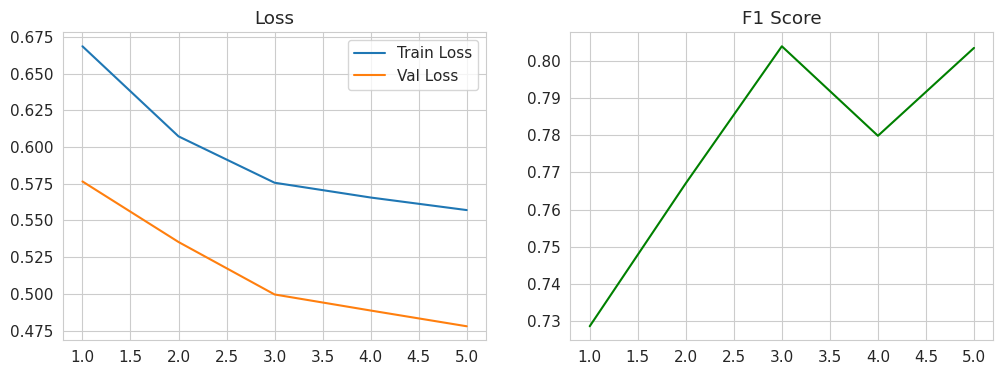

In [ ]:
# ===========================================================================
# Le log de O2 + IoU a été perdu avec la session : on relance les 5 époques pour récupérer les courbes
# ===========================================================================
import json
import matplotlib.pyplot as plt

print("réentraînement de O2 avec la loss IoU")

# O2 était la meilleure configuration
target_mode = 'O2'
print(f"Target Base: {target_mode}")

hist_iou, f1_iou = train_one_config(mode=target_mode, use_iou_loss=True, epochs=5)

log_path = './results/history_iou_O2.json'
with open(log_path, 'w') as f:
    json.dump(hist_iou, f)
    
print(f"historique sauvegardé : {log_path}")
print(f"Final F1: {f1_iou:.4f}")

epochs = range(1, len(hist_iou['train_loss']) + 1)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs, hist_iou['train_loss'], label='Train Loss')
plt.plot(epochs, hist_iou['val_loss'], label='Val Loss')
plt.title('Loss')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(epochs, hist_iou['val_f1'], label='Val F1', color='green')
plt.title('F1 Score')
plt.show()


## Évaluation sur le split test

Chaque checkpoint `best_model_*.pth` (meilleur F1 de validation) est évalué sur les 137 images du split test : matrice de confusion, rapport de classification, et courbes d'apprentissage à partir des fichiers `history_*.json`.


évaluation sur le split test

 PRÉCHARGEMENT 2 TYPES D'IMAGES
Nombre d'échantillons: 137

 Chargement classic...



 Chargement seg...



 1796 images préchargées

modèles trouvés : ['A', 'B', 'C1', 'C2', 'O2', 'O2_iou']

------------------------------------------------------------
modèle A
------------------------------------------------------------


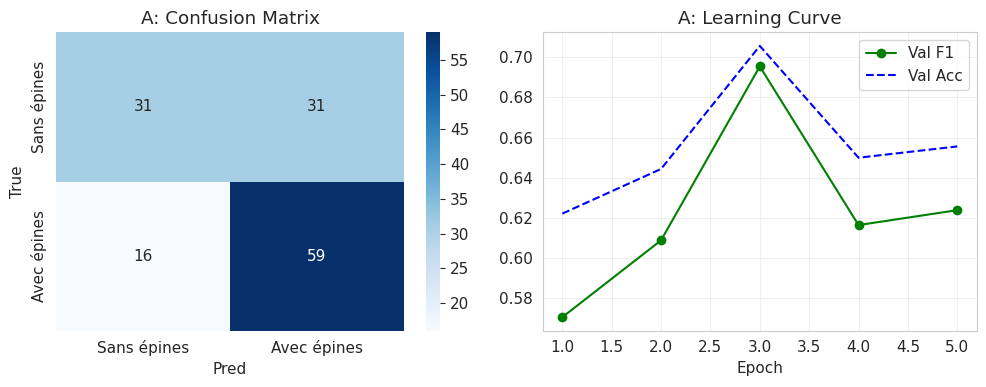

              precision    recall  f1-score   support

 Sans épines       0.66      0.50      0.57        62
 Avec épines       0.66      0.79      0.72        75

    accuracy                           0.66       137
   macro avg       0.66      0.64      0.64       137
weighted avg       0.66      0.66      0.65       137


------------------------------------------------------------
modèle B
------------------------------------------------------------


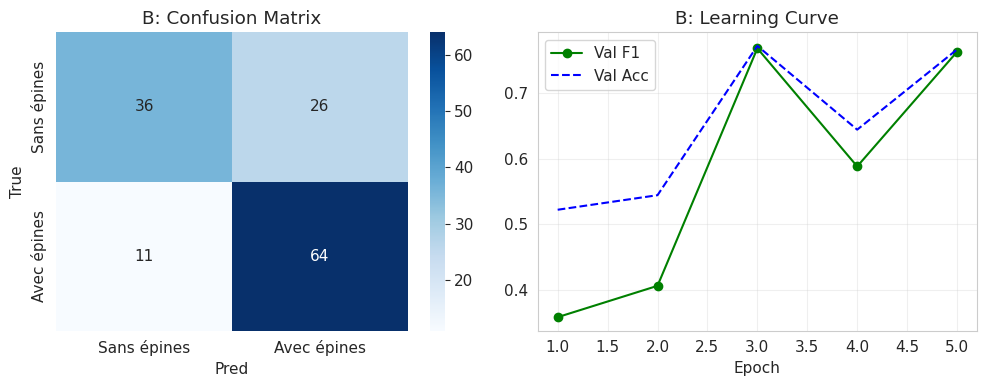

              precision    recall  f1-score   support

 Sans épines       0.77      0.58      0.66        62
 Avec épines       0.71      0.85      0.78        75

    accuracy                           0.73       137
   macro avg       0.74      0.72      0.72       137
weighted avg       0.74      0.73      0.72       137


------------------------------------------------------------
modèle C1
------------------------------------------------------------


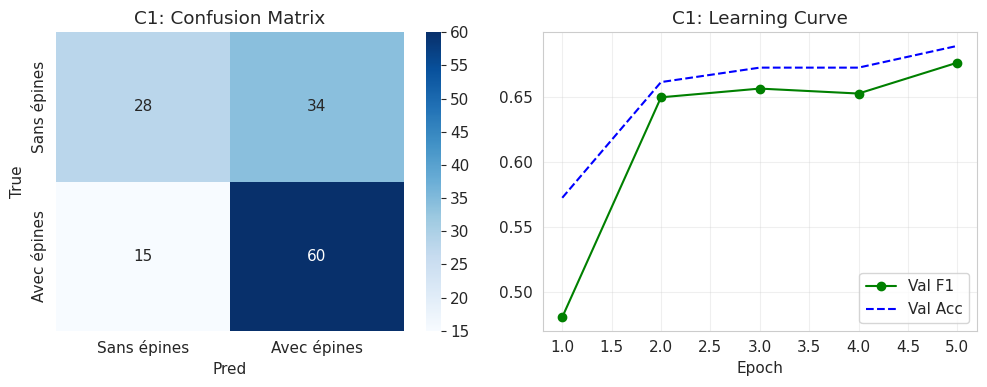

              precision    recall  f1-score   support

 Sans épines       0.65      0.45      0.53        62
 Avec épines       0.64      0.80      0.71        75

    accuracy                           0.64       137
   macro avg       0.64      0.63      0.62       137
weighted avg       0.64      0.64      0.63       137


------------------------------------------------------------
modèle C2
------------------------------------------------------------


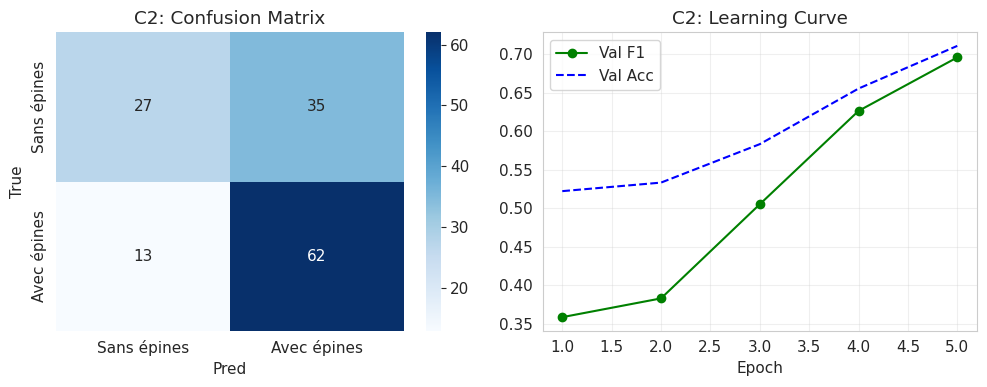

              precision    recall  f1-score   support

 Sans épines       0.68      0.44      0.53        62
 Avec épines       0.64      0.83      0.72        75

    accuracy                           0.65       137
   macro avg       0.66      0.63      0.63       137
weighted avg       0.66      0.65      0.63       137


------------------------------------------------------------
modèle O2
------------------------------------------------------------


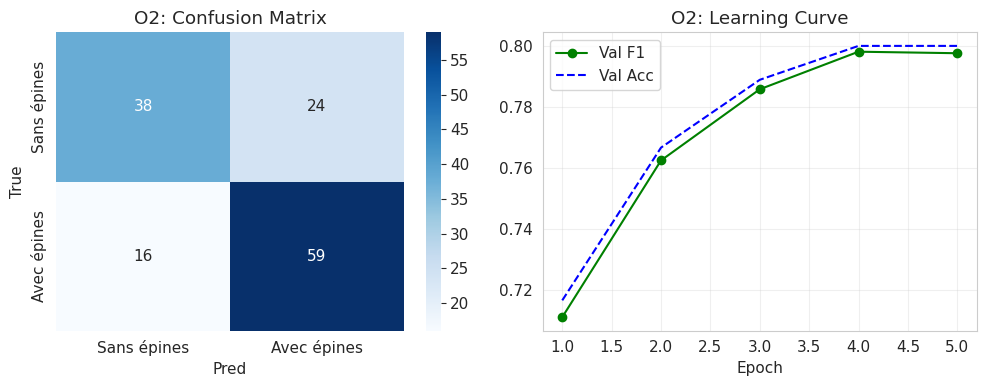

              precision    recall  f1-score   support

 Sans épines       0.70      0.61      0.66        62
 Avec épines       0.71      0.79      0.75        75

    accuracy                           0.71       137
   macro avg       0.71      0.70      0.70       137
weighted avg       0.71      0.71      0.71       137


------------------------------------------------------------
modèle O2_iou
------------------------------------------------------------


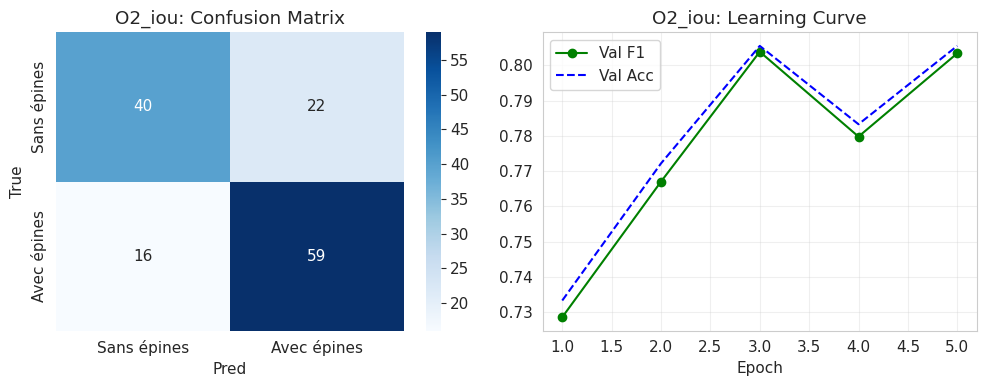

              precision    recall  f1-score   support

 Sans épines       0.71      0.65      0.68        62
 Avec épines       0.73      0.79      0.76        75

    accuracy                           0.72       137
   macro avg       0.72      0.72      0.72       137
weighted avg       0.72      0.72      0.72       137


résumé (test)
 Model      Acc       F1
     B 0.729927 0.723620
O2_iou 0.722628 0.720910
    O2 0.708029 0.705353
     A 0.656934 0.648923
    C2 0.649635 0.634258
    C1 0.642336 0.630081


/tmp/ipykernel_43374/4081431027.py:133: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Model', y='F1', palette='viridis')


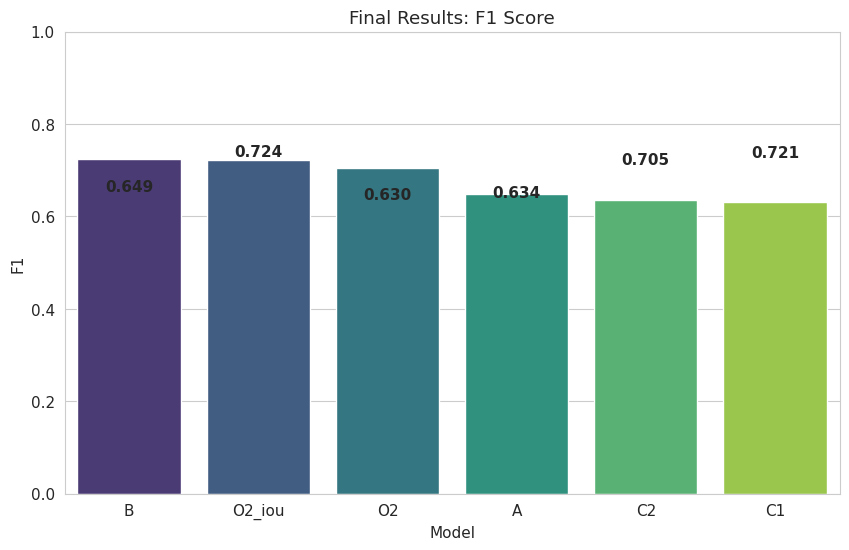

terminé


In [ ]:
# ===========================================================================
# Évaluation finale sur le split test (137 images)
# ===========================================================================
import os
import json
import torch
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

print("évaluation sur le split test")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
save_dir = './results'
os.makedirs(save_dir, exist_ok=True)

if 'test_metadata' not in globals():
    raise RuntimeError("test_metadata manquant : lancer les cellules du haut")

test_dataset_final = DualImageDataset(test_metadata, transform=val_transform, preload=True)
test_loader_final = DataLoader(test_dataset_final, batch_size=CONFIG['BATCH_SIZE'], shuffle=False, num_workers=0)
class_names = ['Sans épines', 'Avec épines']

# checkpoints sauvegardés
files = os.listdir(save_dir)
full_set = []

for f in files:
    if f.startswith('best_model_') and f.endswith('.pth'):
        # Extract name: best_model_ABC.pth -> ABC
        model_name = f.replace('best_model_', '').replace('.pth', '')
        full_set.append(model_name)

full_set = sorted(full_set)
print(f"modèles trouvés : {full_set}")

final_stats = []

for mode in full_set:
    print(f"\n" + "-"*60)
    print(f"modèle {mode}")
    print("-"*60)
    
    pth_path = f'{save_dir}/best_model_{mode}.pth'
    
    arch_mode = mode.replace('_iou', '').replace('_IoU', '') 
    
    model = DualImageCrossViT(
        num_classes=CONFIG['NUM_CLASSES'], img_size=CONFIG['IMAGE_SIZE'],
        patch_size_small=CONFIG['PATCH_SIZE_SMALL'], patch_size_large=CONFIG['PATCH_SIZE_LARGE'],
        embed_dim_small=CONFIG['EMBED_DIM_SMALL'], embed_dim_large=CONFIG['EMBED_DIM_LARGE'],
        depth=CONFIG['DEPTH'], num_heads=CONFIG['NUM_HEADS'], mlp_ratio=CONFIG['MLP_RATIO'],
        qkv_bias=CONFIG['QKV_BIAS'], drop_rate=CONFIG['DROPOUT'], attn_drop_rate=CONFIG['ATTENTION_DROPOUT'],
        in_chans=3, mode=arch_mode
    ).to(device)
    
    model.load_state_dict(torch.load(pth_path, map_location=device))
    model.eval()
    
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for img_nonseg, img_seg, labels, masks in tqdm(test_loader_final, desc=f"Testing {mode}", leave=False):
            img_nonseg, img_seg = img_nonseg.to(device), img_seg.to(device)
            outputs = model(img_nonseg, img_seg)
            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted')
    final_stats.append({'Model': mode, 'Acc': acc, 'F1': f1})
    
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 4))
    
    plt.subplot(1, 2, 1)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'{mode}: Confusion Matrix')
    plt.ylabel('True')
    plt.xlabel('Pred')
    
    hist_file = f'{save_dir}/history_{mode}.json'
    
    # le fichier du run IoU s'appelle history_iou_O2.json
    if not os.path.exists(hist_file) and '_iou' in mode:
         alt_file = f'{save_dir}/history_iou_{arch_mode}.json'
         if os.path.exists(alt_file): hist_file = alt_file

    if os.path.exists(hist_file):
        with open(hist_file, 'r') as f:
            history = json.load(f)
        
        epochs = range(1, len(history['val_f1']) + 1)
        plt.subplot(1, 2, 2)
        plt.plot(epochs, history['val_f1'], 'g-o', label='Val F1')
        plt.plot(epochs, history['val_acc'], 'b--', label='Val Acc')
        plt.title(f'{mode}: Learning Curve')
        plt.xlabel('Epoch')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        plt.subplot(1, 2, 2)
        plt.text(0.5, 0.5, 'Log Not Found', ha='center')
        plt.axis('off')
        
    plt.tight_layout()
    plt.show()
    
    print(classification_report(all_labels, all_preds, target_names=class_names))

print("\n" + "="*60)
print("résumé (test)")
print("="*60)

df = pd.DataFrame(final_stats).sort_values(by='F1', ascending=False)
print(df.to_string(index=False))

plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='Model', y='F1', palette='viridis')
plt.title('F1 sur le split test')
plt.ylim(0, 1.0)
for i, row in df.iterrows():
    plt.text(i, row.F1, f'{row.F1:.3f}', ha='center', va='bottom', fontweight='bold')
plt.show()

print("terminé")